<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/HybridQNN_QFGSM_Akter2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QNN under a Quantum FGSM attack: malware detection on ClaMP (Akter et al., 2024) step by step

This notebook re-implements, runs and checks the method of

> Mst Shapna Akter, Hossain Shahriar, Alfredo Cuzzocrea and Fan Wu,
> "Quantum Adversarial Attacks: Developing Quantum FGSM Algorithm",
> *2024 IEEE 48th Annual Computers, Software, and Applications Conference (COMPSAC)*, pp. 1073-1079, 2024.
> https://doi.org/10.1109/COMPSAC61105.2024.00145

The paper publishes no code, so everything below is written from its four pseudo-code algorithms and its method section,
with the software stack it names (PennyLane, NumPy, scikit-learn).

**What the notebook does.** It downloads the ClaMP malware dataset (5,210 Windows PE files, 69 header features, 52 % malware),
reproduces the paper's preprocessing (shuffle, label-encode the one categorical column, normalise, PCA to 2 components),
cuts the data into the paper's 20 *proportions* (5 %, 10 %, ..., 100 % of the file), and for every proportion trains a classical
neural network (NN) and the paper's PennyLane quantum neural network (QNN: Hadamard layer, `AngleEmbedding` with
$\theta = \arccos\sqrt{x}$, `StronglyEntanglingLayers`, Pauli-Z read-out plus bias, cross-entropy, Adam). Each model is then
attacked three ways as the paper describes: Gaussian random noise on the inputs (Algorithm 3), the classical FGSM on the NN's
inputs, and the paper's **Quantum FGSM (QFGSM)**, which perturbs the *weights and bias of the quantum circuit* by
$\epsilon\,\mathrm{sign}(\nabla \mathcal{L})$ (Algorithm 4). Accuracy, precision, recall and F1 before and after every attack
are tabulated exactly like the paper's Tables I and II. Two classical baselines (random forest, RBF-SVM) are trained on the identical
2-dimensional inputs, an $\epsilon$-sweep and repeated seeds show how robust the numbers are, and the last section puts the
paper's 320 numbers next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs a
pinned PennyLane; if Colab asks to restart the session, restart and run all again. Nothing needs a GPU or a quantum account:
the 2-qubit circuit is simulated exactly with `default.qubit` and differentiated by backpropagation.

**Runtime.** With `FAST_MODE = True` (5 of the 20 proportions, 10 epochs, 2 seeds for the repeat study) the notebook runs in
about 2 minutes on a laptop CPU (expect 3-5 minutes on a Colab CPU). With `FAST_MODE = False` (all 20 proportions, 30 epochs, 3 seeds) it took 21 minutes on the
validation machine (a shared laptop CPU): 16 minutes for the 20 proportions and 4 minutes for the extra seeds. The committed notebook contains the outputs of the run named in the
configuration cell.

**What you get at the end.** The paper's Tables I and II re-computed, accuracy-versus-proportion curves with the paper's values
overlaid, the QNN's decision regions on the PCA plane before and after QFGSM, confusion matrices with malware as the positive
class, classical baselines on the same inputs, an $\epsilon$-sweep, a side-by-side comparison with the paper's numbers, a
critical reading of the paper, and five exercises.

## The paper in one page

**Problem.** Decide from the fields of a Windows executable's PE header whether the file is malware (class 1) or benign
(class 0), and measure how much a small adversarial perturbation degrades a classical and a quantum classifier.

**Decision.** Binary classification of a 2-dimensional PCA projection of 69 header features. The QNN's output is the
expectation value of Pauli-Z on the first qubit plus a trainable bias; a positive output means malware.

**Method.**
1. *Preprocessing* (Section III.B): shuffle, reset index, drop irrelevant columns, encode categorical values, normalise,
   PCA 69 -> 2 components, "balanced sampling by selecting different proportions from the total data set" (20 proportions,
   5 % to 100 % in steps of 5 %).
2. *QNN* (Algorithms 1-2, PennyLane): Hadamard on every qubit, `AngleEmbedding(rotation='Y')` of the angles
   $\theta_{ij} = \arccos\sqrt{x_{ij}}$, `StronglyEntanglingLayers`, $\langle Z_0\rangle$ + bias; cross-entropy loss, Adam /
   gradient descent.
3. *Random noise* (Algorithm 3): $X_{\text{perturbed}} = X + \epsilon N$, $N_{ij} \sim \mathcal{N}(0, 1)$.
4. *FGSM* on the classical NN (standard input-space FGSM, ref. [14] of the paper).
5. *QFGSM* (Algorithm 4, Eq. 1-4): $\nabla_w \mathcal{L}, \nabla_b \mathcal{L} = $ `qml.grad(cost, argnum=[0, 1])`;
   $w' = w + \epsilon\,\mathrm{sign}(\nabla_w \mathcal{L})$, $b' = b + \epsilon\,\mathrm{sign}(\nabla_b \mathcal{L})$. Note that
   the paper's "quantum FGSM" perturbs the *model parameters*, not the inputs.
6. Every model is evaluated on clean data ("before") and after the attack ("after") with accuracy, precision, recall, F1.

**Data.** ClaMP (Kumar, Kuppusamy and Aghila, 2019): 5,210 rows (the paper writes both 5,184 and 5,210; the public CSV is
named `ClaMP_Integrated-5184.csv` and holds 5,210 rows), 69 features (54 raw PE-header fields + 15 derived ones) and the label.

**Claims (Tables I and II, Section IV).**

| Claim | Paper |
|---|---|
| Highest clean accuracy | NN 0.62 (proportion 0.30), QNN 0.68 (proportion 0.25) |
| Random noise (Table I) | performance "tends to decrease", but several proportions stay the same or improve (NN 0.05: 0.54 -> 0.54; QNN 0.15: "0.50 -> 0.52") |
| FGSM on NN (Table II) | lowest post-attack accuracy 0.40 (proportion 0.35) |
| QFGSM on QNN (Table II) | lowest post-attack accuracy 0.21 (proportions 0.15, 0.75, 0.80); QNN "shows a higher degree of vulnerability" than the NN |
| Abstract | QNNs are "significantly" more vulnerable to QFGSM than to random noise |

## What follows the paper and what had to be chosen

The paper fixes the dataset, the PCA dimension, the circuit (Algorithms 1-2), the noise model (Algorithm 3) and the QFGSM
rule (Algorithm 4). It does not give $\epsilon$, the number of `StronglyEntanglingLayers`, the optimiser's learning rate,
epochs or batch size, the train/test split, the classical NN's architecture, which data the attack gradients are computed on,
or how the "before" and "after" metrics are defined. Where the paper is silent this notebook makes a choice and says so in the
code (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | ClaMP, 5,210 rows, 69 features | Same public file (`urwithajit9/ClaMP` on GitHub), downloaded inside the notebook |
| Irrelevant columns | "drop function" (unspecified) | None dropped: all 69 feature columns enter PCA; `packer_type` (the only string column) is label-encoded |
| Normalisation | "normalized to ensure a uniform scale" | `MinMaxScaler` to [0, 1] before PCA, then a second `MinMaxScaler` to [0, 1] on the 2 components (needed by $\arccos\sqrt{x}$); both fitted on the training split only |
| Proportions | 20 sections, 5 % ... 100 %, "balanced sampling" | Class-balanced random draws of round(p x 5,210) rows (at 100 % the whole file, which is 52 : 48) |
| Train / test split | not described | Stratified 80 / 20 inside each proportion, `random_state = SEED` |
| `StronglyEntanglingLayers` depth | not given | 2 layers (12 weights) + bias |
| Loss / read-out | cross-entropy on $\langle Z_0\rangle$ + bias | Binary cross-entropy of `sigmoid(output)`; predict malware when output > 0 |
| Optimiser | "gradient descent and the Adam optimizer" | `qml.AdamOptimizer(0.05)`, mini-batches of 32, 30 epochs (10 in FAST_MODE) |
| Classical NN | "traditional neural network", no details | 2-16-1 MLP (tanh hidden layer, sigmoid output), same loss / optimiser / epochs, written in autograd so FGSM has exact input gradients |
| $\epsilon$ | not given | 0.1 for every attack (10 % of the feature range; 0.1 rad on circuit parameters), plus a sweep 0 ... 0.5 |
| Noise / FGSM target | "perturbation to the training dataset" / "input data" | Perturbed **test** inputs (evasion reading); values clipped back to [0, 1] |
| QFGSM gradient data | Algorithm 4 takes (x, y), unspecified which | Gradient of the training-set loss (white-box attacker); the perturbed model is evaluated on the clean test set |
| "Quantum version" of random noise | Algorithm 3 for both models | Same Gaussian noise added to the QNN's 2 input features before angle encoding |
| Input-space QFGSM | not in the paper | Added for comparison: $x' = x + \epsilon\,\mathrm{sign}(\nabla_x \mathcal{L})$ through the angle encoding |
| Classical baselines | none | Random forest and RBF-SVM on the identical 2-D inputs (plus all 69 features at 100 %) |
| Repeats | single run | 3 seeds at proportion 1.0 (2 in FAST_MODE), mean +- std |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in about 4 minutes. False: all 20 proportions, 30 epochs (about 25 min on CPU).

SEED       = 42             # CHOICE: the paper gives no seed
N_QUBITS   = 2              # paper: 69 features -> 2 principal components -> 2 qubits (one angle per qubit)
N_LAYERS   = 2              # CHOICE: depth of StronglyEntanglingLayers (paper does not say)
TEST_SIZE  = 0.2            # CHOICE: stratified hold-out inside each proportion (paper does not describe the split)

# The paper's 20 "proportions" of the dataset (5 % ... 100 %); FAST_MODE keeps five of them
PROPORTIONS = [0.05, 0.10, 0.25, 0.50, 1.00] if FAST_MODE else [round(0.05 * k, 2) for k in range(1, 21)]

EPOCHS     = 10 if FAST_MODE else 30   # CHOICE: paper gives no epoch count
BATCH_SIZE = 32             # CHOICE: mini-batch size for Adam
LR         = 0.05           # CHOICE: Adam step size (paper: "gradient descent and the Adam optimizer")
HIDDEN     = 16             # CHOICE: hidden units of the classical NN (paper gives no architecture)

EPS        = 0.1            # CHOICE: perturbation magnitude for random noise, FGSM and QFGSM (paper gives no value)
EPS_SWEEP  = [0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
REPEAT_SEEDS = [SEED + 1] if FAST_MODE else [SEED + 1, SEED + 2]   # extra seeds at proportion 1.0 (mean +- std)

DATA_DIR   = "data"         # where the CSV is cached (relative to the working directory)
DATA_FILE  = "ClaMP_Integrated-5184.csv"
DATA_URLS  = ["https://raw.githubusercontent.com/urwithajit9/ClaMP/master/dataset/ClaMP_Integrated-5184.csv",
              "https://github.com/urwithajit9/ClaMP/raw/master/dataset/ClaMP_Integrated-5184.csv",
              "https://raw.githubusercontent.com/urwithajit9/ClaMP/main/dataset/ClaMP_Integrated-5184.csv"]
DATA_SOURCE = "download"    # "download" (default) or "upload": put the CSV into DATA_DIR yourself

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

import pennylane as qml
from pennylane import numpy as pnp          # autograd-backed NumPy: every array can carry a gradient

np.random.seed(SEED)                        # seeds everywhere: NumPy, our generator, scikit-learn random_state=SEED below
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

import sklearn
print("pennylane", qml.version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| proportions:", PROPORTIONS, "| epochs:", EPOCHS, "| eps:", EPS)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | proportions: [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0] | epochs: 30 | eps: 0.1


## 1. The ClaMP malware dataset

ClaMP ("Classification of Malware with PE headers", Kumar, Kuppusamy and Aghila, *J. King Saud Univ. CIS* 31(2), 2019) describes
each Windows executable by fields of its PE header: the DOS header (`e_cblp`, `e_lfanew`, ...), the file header
(`NumberOfSections`, 15 characteristic flags `FH_char*`), the optional header (`SizeOfCode`, `AddressOfEntryPoint`,
`ImageBase`, `CheckSum`, 11 DLL-characteristic flags `OH_DLLchar*`, ...) and 15 *derived* features (suspicious section
counts, packer presence and type, section entropies, file size and entropy). The label `class` is 1 for malware (collected
from VirusShare) and 0 for benign files (Windows XP / 7 program files and free-software archives).

The paper uses the *integrated* file (raw + derived features, 69 columns + label). The cell below downloads it from the
authors' GitHub repository (several mirrors of the same raw URL are tried) and caches it in `DATA_DIR`; set
`DATA_SOURCE = "upload"` and copy the CSV there yourself if the download is blocked.

In [4]:
CSV_PATH = os.path.join(DATA_DIR, DATA_FILE)

def fetch_clamp(path):
    if os.path.exists(path):
        print("using cached", path)
        return pd.read_csv(path)
    if DATA_SOURCE == "upload":
        raise FileNotFoundError(f"DATA_SOURCE='upload' but {path} is missing")
    import requests
    last = None
    for url in DATA_URLS:                                   # try each mirror in turn
        try:
            r = requests.get(url, timeout=120); r.raise_for_status()
            with open(path, "wb") as f:
                f.write(r.content)
            print("downloaded", url)
            return pd.read_csv(path)
        except Exception as e:
            last = e; print("failed:", url, "->", type(e).__name__)
    raise RuntimeError(f"could not download ClaMP: {last}")

t0 = time.time()
df = fetch_clamp(CSV_PATH)
print(f"loaded in {time.time()-t0:.1f} s: {df.shape[0]:,} rows x {df.shape[1]} columns  (paper: 5,210 rows, 69 features + label)")
print("missing values:", int(df.isnull().sum().sum()))
counts = df["class"].value_counts()
print("class counts  :", {"malware (1)": int(counts[1]), "benign (0)": int(counts[0])},
      f"-> malware share {counts[1] / len(df):.1%}   (paper: category 1 = 52.2 %)")
print("non-numeric columns:", [c for c in df.columns if df[c].dtype == object or str(df[c].dtype).startswith("str")])
df.head(3)

using cached data\ClaMP_Integrated-5184.csv
loaded in 0.1 s: 5,210 rows x 70 columns  (paper: 5,210 rows, 69 features + label)
missing values: 0
class counts  : {'malware (1)': 2722, 'benign (0)': 2488} -> malware share 52.2%   (paper: category 1 = 52.2 %)
non-numeric columns: ['packer_type']


,e_cblp,e_cp,e_cparhdr,e_maxalloc,e_sp,e_lfanew,NumberOfSections,CreationYear,FH_char0,FH_char1,FH_char2,FH_char3,FH_char4,FH_char5,FH_char6,FH_char7,FH_char8,FH_char9,FH_char10,FH_char11,...,OH_DLLchar6,OH_DLLchar7,OH_DLLchar8,OH_DLLchar9,OH_DLLchar10,SizeOfStackReserve,SizeOfStackCommit,SizeOfHeapReserve,SizeOfHeapCommit,LoaderFlags,sus_sections,non_sus_sections,packer,packer_type,E_text,E_data,filesize,E_file,fileinfo,class
0,144,3,4,65535,184,256,4,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1048576,4096,1048576,4096,1,1,3,0,NoPacker,6.603616,5.443362,1181520,6.627552,1,0
1,144,3,4,65535,184,184,4,1,0,1,1,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1048576,4096,1048576,4096,1,1,3,0,NoPacker,5.205926,2.123522,7680,5.318221,0,0
2,144,3,4,65535,184,272,5,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1048576,4096,1048576,4096,1,1,4,0,NoPacker,6.238000,3.380859,57872,6.507758,1,0


## 2. Preprocessing: encode, normalise, PCA to two components, 20 proportions

The paper's pipeline is: shuffle, reset the index, drop irrelevant columns, encode categorical values, normalise, PCA from 69
to 2 components. The only categorical column is `packer_type` (strings such as `NoPacker`, `UPX`), which we label-encode; the
paper does not list the columns it dropped, so none are dropped here (constant columns are harmless to min-max scaling and
PCA).

Two details that the paper leaves open matter for the quantum model:

* The angle encoding $\theta = \arccos\sqrt{x}$ needs $x \in [0, 1]$. Principal components are not bounded, so a second
  min-max scaler maps each component to [0, 1]; test values are clipped to the training range.
* The paper evaluates 20 *proportions* of the data (5 %, 10 %, ..., 100 %) with "balanced sampling". For every proportion
  we draw a class-balanced random sample of round(p x 5,210) rows (at 100 % the whole, mildly imbalanced file), split it
  stratified 80 / 20, and fit scaler and PCA on that training split only.

Why PCA to two components? "Given the limited number of available qubits" the paper keeps one qubit per feature. The scatter
plot below shows what the quantum model will actually see: at 100 % the two components explain roughly 47 % of the variance of
the min-max-scaled features, and the two classes are already well separated along the first component.

69 feature columns (paper: 69); packer_type encoded as 40 integer codes


,proportion,rows,train,test,malware share (train),PCA explained variance
0,0.05,260,208,52,0.500,0.474
1,0.10,521,416,105,0.500,0.438
2,0.15,782,625,157,0.501,0.476
3,0.20,1042,833,209,0.501,0.444
4,0.25,1302,1041,261,0.500,0.471
5,0.30,1563,1250,313,0.500,0.478
6,0.35,1823,1458,365,0.500,0.467
7,0.40,2084,1667,417,0.500,0.466
8,0.45,2344,1875,469,0.500,0.465
9,0.50,2605,2084,521,0.500,0.469


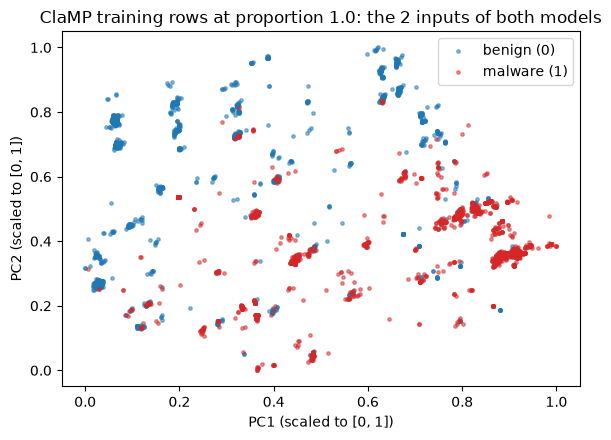

In [5]:
feature_cols = [c for c in df.columns if c != "class"]
df_num = df.copy()
df_num["packer_type"] = LabelEncoder().fit_transform(df["packer_type"].astype(str))   # paper: "encoder from the sklearn library"
X_all = df_num[feature_cols].values.astype(float)
y_all = df_num["class"].values.astype(int)
print(f"{len(feature_cols)} feature columns (paper: 69); packer_type encoded as {df_num['packer_type'].nunique()} integer codes")

def balanced_indices(n, seed):
    '''# CHOICE: n/2 malware + n/2 benign rows drawn at random; a class that is too small gives all its rows and the other
    class fills up (only happens at p = 1.0, where the sample is simply the whole file).'''
    r = np.random.default_rng(seed)
    idx1, idx0 = np.flatnonzero(y_all == 1), np.flatnonzero(y_all == 0)
    k1, k0 = min(n // 2, len(idx1)), min(n - n // 2, len(idx0))
    k1 = min(n - k0, len(idx1)); k0 = min(n - k1, len(idx0))
    pick = np.concatenate([r.choice(idx1, k1, replace=False), r.choice(idx0, k0, replace=False)])
    return r.permutation(pick)                                       # paper: shuffle

def make_proportion(p, seed=SEED):
    '''One of the paper's 'sections': balanced sample -> stratified split -> MinMax -> PCA(2) -> MinMax to [0, 1].'''
    n = int(round(p * len(df_num)))
    idx = balanced_indices(n, seed)
    X, y = X_all[idx], y_all[idx]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)   # CHOICE: 80/20
    scaler = MinMaxScaler().fit(Xtr)                                                 # paper: normalise (fit on train only)
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(scaler.transform(Xtr))   # paper: 69 -> 2 components
    pc_scaler = MinMaxScaler().fit(pca.transform(scaler.transform(Xtr)))             # CHOICE: components -> [0, 1]
    tf = lambda A: np.clip(pc_scaler.transform(pca.transform(scaler.transform(A))), 0.0, 1.0)
    return dict(p=p, n=n, X_train=tf(Xtr), y_train=ytr, X_test=tf(Xte), y_test=yte,
                explained=pca.explained_variance_ratio_, raw_train=scaler.transform(Xtr), raw_test=scaler.transform(Xte))

sections = {p: make_proportion(p) for p in PROPORTIONS}
summary = pd.DataFrame([{"proportion": p, "rows": s["n"], "train": len(s["y_train"]), "test": len(s["y_test"]),
                         "malware share (train)": round(s["y_train"].mean(), 3),
                         "PCA explained variance": round(float(s["explained"].sum()), 3)} for p, s in sections.items()])
display(summary)

s = sections[max(PROPORTIONS)]
fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, col, lab in [(0, "tab:blue", "benign (0)"), (1, "tab:red", "malware (1)")]:
    m = s["y_train"] == cls
    ax.scatter(s["X_train"][m, 0], s["X_train"][m, 1], s=6, alpha=0.5, c=col, label=lab)
ax.set_xlabel("PC1 (scaled to [0, 1])"); ax.set_ylabel("PC2 (scaled to [0, 1])")
ax.set_title(f"ClaMP training rows at proportion {s['p']}: the 2 inputs of both models"); ax.legend()
plt.tight_layout(); plt.show()

## 3. The two models: a classical NN and the paper's PennyLane QNN (Algorithms 1 and 2)

**QNN.** Algorithm 1 is reproduced literally: a Hadamard on every qubit, `AngleEmbedding(rotation='Y')` of the encoded
features, `StronglyEntanglingLayers`, and $\langle Z_0 \rangle$. Algorithm 2 adds a bias. The paper's angle encoding
$\theta_{ij} = \arccos\sqrt{x_{ij}}$ maps $x = 0$ to $\pi/2$ and $x = 1$ to $0$ (a monotone, non-linear squeeze of the unit
interval). Starting from $|+\rangle$ (after the Hadamard), the $R_Y(\theta)$ rotation then prepares a state whose Z-expectation
is $-\sin\theta$, so the encoding is well defined for every $x \in [0, 1]$. The loss is the binary cross-entropy of
`sigmoid(output)`; the paper says "cross-entropy" without saying how the real-valued output is turned into a probability.

**NN.** The paper does not describe its "traditional neural network". We use a 2-16-1 multilayer perceptron with a tanh
hidden layer and a sigmoid output, trained with the same loss, optimiser, batch size and epochs as the QNN. It is written in
autograd (the differentiation engine behind `pennylane.numpy`) so that the FGSM gradient with respect to the inputs is exact,
and so that no deep-learning framework is needed.

Both models are trained by `qml.AdamOptimizer` on mini-batches; the full-training-set loss is recorded after every epoch.

QNN: 2 qubits, StronglyEntanglingLayers shape (2, 2, 3) = 12 weights + 1 bias
NN : 2-16-1 MLP = 65 parameters
example row [0.782 0.47 ] -> angles [0.485 0.815] rad


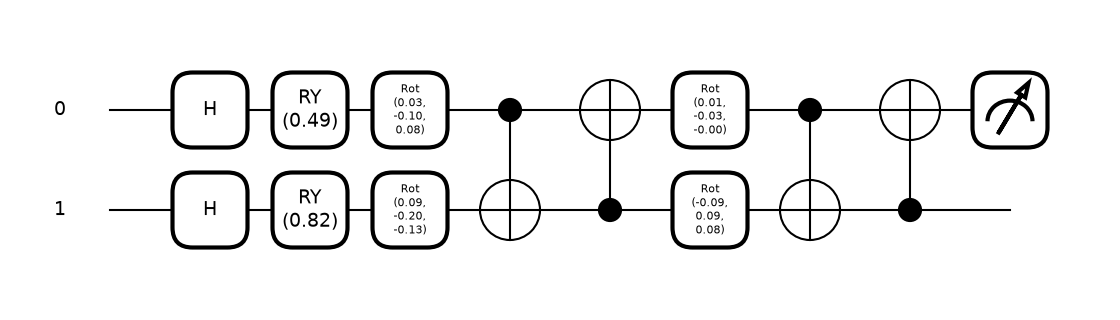

In [6]:
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def quantum_circuit(parameters, data):
    '''Algorithm 1 of the paper (data = encoded angles, one per qubit; a batch of rows is broadcast).'''
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
    qml.AngleEmbedding(features=data, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights=parameters, wires=range(N_QUBITS))
    return qml.expval(qml.PauliZ(0))

def angle_encode(x):
    '''Paper: theta = arccos(sqrt(x)); x is kept strictly inside (0, 1) so the gradient through sqrt/arccos stays finite.'''
    return pnp.arccos(pnp.sqrt(pnp.clip(x, 1e-6, 1.0 - 1e-6)))

def variational_classifier(weights, bias, x):
    '''Algorithm 2 of the paper: circuit output + bias (malware if > 0).'''
    return quantum_circuit(weights, angle_encode(x)) + bias

def bce(output, y):
    '''Binary cross-entropy of sigmoid(output).  # CHOICE: how the real-valued output becomes a probability'''
    p = pnp.clip(1.0 / (1.0 + pnp.exp(-output)), 1e-7, 1.0 - 1e-7)
    return -pnp.mean(y * pnp.log(p) + (1 - y) * pnp.log(1 - p))

def qnn_cost(weights, bias, x, y):
    return bce(variational_classifier(weights, bias, x), y)

def qnn_predict(weights, bias, X):
    return np.asarray(variational_classifier(weights, bias, np.asarray(X, dtype=float)) > 0).astype(int)

# ---- classical NN (2 -> HIDDEN -> 1), same loss, written in autograd ----
def nn_forward(W1, b1, W2, b2, x):
    h = pnp.tanh(pnp.dot(x, W1) + b1)
    return pnp.dot(h, W2)[:, 0] + b2

def nn_cost(W1, b1, W2, b2, x, y):
    return bce(nn_forward(W1, b1, W2, b2, x), y)

def nn_predict(params, X):
    return np.asarray(nn_forward(*params, np.asarray(X, dtype=float)) > 0).astype(int)

def minibatch_train(cost, params, Xtr, ytr, seed, epochs=EPOCHS):
    '''Adam on mini-batches; returns the final parameters and the full-training-set loss after every epoch.'''
    r = np.random.default_rng(seed)
    opt = qml.AdamOptimizer(stepsize=LR)
    X = np.asarray(Xtr, dtype=float); Y = np.asarray(ytr, dtype=float)   # plain arrays = non-trainable inputs
    losses = []
    for ep in range(epochs):
        perm = r.permutation(len(Xtr))
        for i in range(0, len(Xtr), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            out = opt.step(cost, *params, X[b], Y[b])
            params = list(out[:len(params)])
        losses.append(float(cost(*params, X, Y)))
    return params, losses

def train_qnn(Xtr, ytr, seed):
    r = np.random.default_rng(seed)
    weights = pnp.array(r.normal(0, 0.1, qml.StronglyEntanglingLayers.shape(N_LAYERS, N_QUBITS)), requires_grad=True)
    bias = pnp.array(0.0, requires_grad=True)
    (weights, bias), losses = minibatch_train(qnn_cost, [weights, bias], Xtr, ytr, seed)
    return weights, bias, losses

def train_nn(Xtr, ytr, seed):
    r = np.random.default_rng(seed)
    params = [pnp.array(r.normal(0, 0.5, (N_QUBITS, HIDDEN)), requires_grad=True), pnp.array(np.zeros(HIDDEN), requires_grad=True),
              pnp.array(r.normal(0, 0.5, (HIDDEN, 1)), requires_grad=True), pnp.array(0.0, requires_grad=True)]
    return minibatch_train(nn_cost, params, Xtr, ytr, seed)

w_demo = pnp.array(rng.normal(0, 0.1, qml.StronglyEntanglingLayers.shape(N_LAYERS, N_QUBITS)), requires_grad=True)
print(f"QNN: {N_QUBITS} qubits, StronglyEntanglingLayers shape {w_demo.shape} = {w_demo.size} weights + 1 bias")
print(f"NN : 2-{HIDDEN}-1 MLP = {N_QUBITS * HIDDEN + HIDDEN + HIDDEN + 1} parameters")
x_demo = sections[max(PROPORTIONS)]["X_train"][:1]
print("example row", np.round(x_demo[0], 3), "-> angles", np.round(np.asarray(angle_encode(pnp.array(x_demo)))[0], 3), "rad")
fig, ax = qml.draw_mpl(quantum_circuit, decimals=2, level="device")(w_demo, angle_encode(pnp.array(x_demo[0])))   # expanded to the gates the simulator runs
plt.show()

## 4. The attacks: random noise (Algorithm 3), FGSM, and Quantum FGSM (Algorithm 4)

* **Random noise** (Algorithm 3, used for both models): add $\epsilon N$ with $N_{ij} \sim \mathcal{N}(0,1)$ to the input
  matrix. The paper calls the same procedure applied to the QNN's inputs the "quantum version" of random noise.
* **FGSM** (classical NN): $x' = x + \epsilon\,\mathrm{sign}(\nabla_x \mathcal{L}(x, y))$, the standard white-box
  evasion attack of Goodfellow et al. that the paper takes from ref. [14].
* **QFGSM** (Algorithm 4, Eq. 1-4): compute $\nabla_w \mathcal{L}$ and $\nabla_b \mathcal{L}$ with
  `qml.grad(cost, argnum=[0, 1])` (`argnums` in PennyLane 0.45), and move the **circuit weights and bias** one signed step of
  size $\epsilon$ uphill. The attacked object is the trained model, not the data: the "adversarial examples" of the paper are
  perturbed parameter sets, and the "after attack" numbers are the perturbed model's scores on the clean test set.
* **Input-space QFGSM** (not in the paper, added for comparison): the classical FGSM rule applied to the QNN, with the
  gradient taken through the angle encoding and the circuit.

Perturbed inputs are clipped back to the feature range [0, 1] (`# CHOICE`), as is standard for FGSM on bounded inputs, and
the attack gradients of QFGSM are computed on the training set (`# CHOICE`: a white-box attacker who knows model and data).

In [7]:
def add_perturbation(data, epsilon, r):
    '''Algorithm 3 of the paper: data + epsilon * N(0, 1) noise.  # CHOICE: clipped to the feature range [0, 1].'''
    noise = r.standard_normal(data.shape)
    return np.clip(data + epsilon * noise, 0.0, 1.0)

def fgsm_nn(params, X, y, epsilon):
    '''Classical FGSM on the NN's inputs: x + eps * sign(dL/dx).'''
    Y = np.asarray(y, dtype=float)
    grad_x = qml.grad(lambda x: nn_cost(*params, x, Y))(pnp.array(X, requires_grad=True))
    return np.clip(X + epsilon * np.sign(np.asarray(grad_x)), 0.0, 1.0)

def quantum_fgsm(weights, bias, x, y, epsilon):
    '''Algorithm 4 of the paper: perturb the circuit weights and bias by eps * sign(gradient of the cost).'''
    gradient_fn = qml.grad(qnn_cost, argnums=[0, 1])                      # paper: qml.grad(cost_fn, argnum=[0, 1])
    gradient_weights, gradient_bias = gradient_fn(weights, bias, np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    perturbation_weights = epsilon * pnp.sign(gradient_weights)
    perturbation_bias = epsilon * pnp.sign(gradient_bias)
    return weights + perturbation_weights, bias + perturbation_bias

def qfgsm_input(weights, bias, X, y, epsilon):
    '''Input-space variant (addition): x + eps * sign(dL/dx) through the angle encoding and the circuit.'''
    Y = np.asarray(y, dtype=float)
    grad_x = qml.grad(lambda x: qnn_cost(weights, bias, x, Y))(pnp.array(X, requires_grad=True))
    return np.clip(X + epsilon * np.sign(np.asarray(grad_x)), 0.0, 1.0)

def metrics(y_true, y_pred):
    '''Paper's four metrics with malware (class 1) as the positive class.'''
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, pos_label=1, zero_division=0),
                recall=recall_score(y_true, y_pred, pos_label=1, zero_division=0),
                f1=f1_score(y_true, y_pred, pos_label=1, zero_division=0))

# quick sanity check on an untrained circuit: QFGSM must move every parameter by exactly +-eps
s = sections[max(PROPORTIONS)]
w_adv, b_adv = quantum_fgsm(w_demo, pnp.array(0.0, requires_grad=True), s["X_train"][:64], s["y_train"][:64], EPS)
print("QFGSM parameter shifts (should all be +-%.2f):" % EPS, np.unique(np.round(np.asarray(w_adv - w_demo), 4)))
x_adv = qfgsm_input(w_demo, pnp.array(0.0, requires_grad=True), s["X_test"][:5], s["y_test"][:5], EPS)
print("input-space step, mean |dx| per feature (<= eps because of clipping):", np.round(np.abs(x_adv - s["X_test"][:5]).mean(0), 3))

QFGSM parameter shifts (should all be +-0.10): [-0.1  0.1]
input-space step, mean |dx| per feature (<= eps because of clipping): [0.077 0.1  ]


## 5. Classical baselines on identical inputs

The paper compares the NN and the QNN only with each other. Before training either, we ask what a random forest and an
RBF support-vector machine achieve on exactly the same two scaled principal components, for every proportion, on clean and on
noise-perturbed test rows (the same Algorithm 3 noise, same $\epsilon$). At 100 % we also train the random forest on all 69
min-max-scaled features to show what the PCA step throws away.

In [8]:
baseline_rows = []
for p, s in sections.items():
    r = np.random.default_rng(SEED + 1000)
    X_noisy = add_perturbation(s["X_test"], EPS, r)
    for name, model in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED)),
                        ("SVC (rbf)", SVC(kernel="rbf", C=1.0, random_state=SEED))]:
        t0 = time.perf_counter(); model.fit(s["X_train"], s["y_train"]); fit_s = time.perf_counter() - t0
        clean = metrics(s["y_test"], model.predict(s["X_test"]))
        noisy = metrics(s["y_test"], model.predict(X_noisy))
        baseline_rows.append(dict(proportion=p, model=name, inputs="2 PCA components", fit_s=round(fit_s, 2),
                                  acc_clean=clean["accuracy"], f1_clean=clean["f1"], acc_noise=noisy["accuracy"], f1_noise=noisy["f1"]))
p_max = max(PROPORTIONS); s = sections[p_max]
rf_all = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(s["raw_train"], s["y_train"])
m_all = metrics(s["y_test"], rf_all.predict(s["raw_test"]))
baseline_rows.append(dict(proportion=p_max, model="RandomForest", inputs="all 69 features", fit_s=None,
                          acc_clean=m_all["accuracy"], f1_clean=m_all["f1"], acc_noise=None, f1_noise=None))
baseline_df = pd.DataFrame(baseline_rows).round(3)
display(baseline_df)

,proportion,model,inputs,fit_s,acc_clean,f1_clean,acc_noise,f1_noise
0,0.05,RandomForest,2 PCA components,0.38,0.942,0.941,0.827,0.830
1,0.05,SVC (rbf),2 PCA components,0.00,0.923,0.929,0.865,0.873
2,0.10,RandomForest,2 PCA components,0.38,0.924,0.923,0.838,0.841
3,0.10,SVC (rbf),2 PCA components,0.01,0.914,0.917,0.857,0.862
4,0.15,RandomForest,2 PCA components,0.42,0.962,0.962,0.828,0.840
5,0.15,SVC (rbf),2 PCA components,0.01,0.924,0.925,0.854,0.864
6,0.20,RandomForest,2 PCA components,0.35,0.943,0.943,0.823,0.825
7,0.20,SVC (rbf),2 PCA components,0.01,0.885,0.891,0.880,0.886
8,0.25,RandomForest,2 PCA components,0.39,0.966,0.966,0.835,0.839
9,0.25,SVC (rbf),2 PCA components,0.01,0.920,0.921,0.870,0.874


## 6. The proportion experiment (the paper's Tables I and II)

For every proportion the loop trains the NN and the QNN on the clean training split, scores both on the clean test split
("before"), then applies the attacks and scores again ("after"):

| Model | Random noise (Table I) | FGSM / QFGSM (Table II) |
|---|---|---|
| NN | noisy test inputs (Algorithm 3) | FGSM on test inputs |
| QNN | noisy test inputs before angle encoding ("quantum version") | QFGSM on weights and bias (Algorithm 4), clean test inputs; plus the input-space variant |

Training times and the per-epoch loss curves are kept for the figures. At the largest proportion the predictions are also
stored for the confusion matrices.

In [9]:
rows, losses, models, preds = [], {}, {}, {}
t_start = time.perf_counter()
for p, s in sections.items():
    r = np.random.default_rng(SEED + int(round(p * 100)))
    Xtr, ytr, Xte, yte = s["X_train"], s["y_train"], s["X_test"], s["y_test"]
    X_noisy = add_perturbation(Xte, EPS, r)

    t0 = time.perf_counter(); nn_params, nn_losses = train_nn(Xtr, ytr, SEED); t_nn = time.perf_counter() - t0
    t0 = time.perf_counter(); w, b, q_losses = train_qnn(Xtr, ytr, SEED);     t_qnn = time.perf_counter() - t0
    losses[p] = dict(NN=nn_losses, QNN=q_losses); models[p] = dict(nn=nn_params, qnn=(w, b))

    nn_before = nn_predict(nn_params, Xte)
    nn_noise  = nn_predict(nn_params, X_noisy)
    nn_fgsm   = nn_predict(nn_params, fgsm_nn(nn_params, Xte, yte, EPS))
    q_before  = qnn_predict(w, b, Xte)
    q_noise   = qnn_predict(w, b, X_noisy)
    w_adv, b_adv = quantum_fgsm(w, b, Xtr, ytr, EPS)                        # Algorithm 4, gradient on the training set
    q_qfgsm   = qnn_predict(w_adv, b_adv, Xte)
    q_qfgsm_x = qnn_predict(w, b, qfgsm_input(w, b, Xte, yte, EPS))

    for model, attack, phase, pred, secs in [("NN", "random noise", "before", nn_before, t_nn), ("NN", "random noise", "after", nn_noise, t_nn),
                                             ("NN", "FGSM", "before", nn_before, t_nn),         ("NN", "FGSM", "after", nn_fgsm, t_nn),
                                             ("QNN", "random noise", "before", q_before, t_qnn), ("QNN", "random noise", "after", q_noise, t_qnn),
                                             ("QNN", "QFGSM", "before", q_before, t_qnn),        ("QNN", "QFGSM", "after", q_qfgsm, t_qnn),
                                             ("QNN", "QFGSM (input)", "before", q_before, t_qnn), ("QNN", "QFGSM (input)", "after", q_qfgsm_x, t_qnn)]:
        rows.append(dict(proportion=p, model=model, attack=attack, phase=phase, train_s=secs, **metrics(yte, pred)))
    if p == max(PROPORTIONS):
        preds = dict(y=yte, nn_before=nn_before, nn_fgsm=nn_fgsm, nn_noise=nn_noise, q_before=q_before, q_qfgsm=q_qfgsm, q_noise=q_noise, q_qfgsm_x=q_qfgsm_x)
    print(f"p={p:.2f} n_train={len(ytr):4d} | NN {t_nn:5.1f}s acc {metrics(yte, nn_before)['accuracy']:.3f} -> noise {metrics(yte, nn_noise)['accuracy']:.3f}, FGSM {metrics(yte, nn_fgsm)['accuracy']:.3f}"
          f" | QNN {t_qnn:5.1f}s acc {metrics(yte, q_before)['accuracy']:.3f} -> noise {metrics(yte, q_noise)['accuracy']:.3f}, QFGSM {metrics(yte, q_qfgsm)['accuracy']:.3f}, QFGSM(input) {metrics(yte, q_qfgsm_x)['accuracy']:.3f}")
results = pd.DataFrame(rows)
print(f"total {(time.perf_counter() - t_start) / 60:.1f} min")

p=0.05 n_train= 208 | NN   0.5s acc 0.846 -> noise 0.865, FGSM 0.731 | QNN   4.0s acc 0.808 -> noise 0.788, QFGSM 0.788, QFGSM(input) 0.769


p=0.10 n_train= 416 | NN   0.9s acc 0.857 -> noise 0.810, FGSM 0.752 | QNN   7.8s acc 0.838 -> noise 0.819, QFGSM 0.743, QFGSM(input) 0.695


p=0.15 n_train= 625 | NN   1.4s acc 0.885 -> noise 0.911, FGSM 0.777 | QNN  12.0s acc 0.803 -> noise 0.822, QFGSM 0.732, QFGSM(input) 0.713


p=0.20 n_train= 833 | NN   2.0s acc 0.880 -> noise 0.856, FGSM 0.727 | QNN  18.9s acc 0.809 -> noise 0.770, QFGSM 0.517, QFGSM(input) 0.675


p=0.25 n_train=1041 | NN   2.5s acc 0.920 -> noise 0.889, FGSM 0.774 | QNN  28.1s acc 0.762 -> noise 0.770, QFGSM 0.579, QFGSM(input) 0.567


...

p=0.80 n_train=3334 | NN   4.9s acc 0.910 -> noise 0.847, FGSM 0.685 | QNN  52.2s acc 0.805 -> noise 0.797, QFGSM 0.669, QFGSM(input) 0.721


p=0.85 n_train=3542 | NN   6.8s acc 0.927 -> noise 0.866, FGSM 0.774 | QNN  93.4s acc 0.799 -> noise 0.800, QFGSM 0.674, QFGSM(input) 0.704


p=0.90 n_train=3751 | NN  14.9s acc 0.923 -> noise 0.844, FGSM 0.756 | QNN 110.5s acc 0.805 -> noise 0.784, QFGSM 0.658, QFGSM(input) 0.689


p=0.95 n_train=3960 | NN  11.8s acc 0.897 -> noise 0.837, FGSM 0.709 | QNN  85.8s acc 0.797 -> noise 0.801, QFGSM 0.576, QFGSM(input) 0.690


p=1.00 n_train=4168 | NN   6.2s acc 0.915 -> noise 0.856, FGSM 0.760 | QNN  85.4s acc 0.798 -> noise 0.803, QFGSM 0.617, QFGSM(input) 0.724
total 16.3 min


## 7. Results: the paper's tables and figures re-drawn

The paper's Table I (random noise) and Table II (FGSM / QFGSM) list, per model and proportion, the four metrics before and
after the attack. The same layout is produced below, followed by accuracy-versus-proportion curves with the paper's
values overlaid, the loss curves, the QNN's decision regions on the PCA plane before and after QFGSM, and confusion matrices
(malware = positive class) at the largest proportion.

This notebook's Table I: random noise, eps = 0.1


phase              before                           after                       
           model accuracy precision recall    f1 accuracy precision recall    f1
proportion                                                                      
0.05          NN     0.85      0.85   0.85  0.85     0.87      0.85   0.88  0.87
0.10          NN     0.86      0.88   0.83  0.85     0.81      0.86   0.73  0.79
0.15          NN     0.89      0.83   0.97  0.89     0.91      0.86   0.99  0.92
0.20          NN     0.88      0.87   0.89  0.88     0.86      0.86   0.86  0.86
0.25          NN     0.92      0.90   0.95  0.92     0.89      0.86   0.92  0.89
0.30          NN     0.91      0.87   0.97  0.92     0.87      0.84   0.90  0.87
0.35          NN     0.89      0.84   0.95  0.89     0.88      0.85   0.92  0.88
0.40          NN     0.91      0.89   0.93  0.91     0.84      0.84   0.84  0.84
0.45          NN     0.93      0.90   0.97  0.93     0.85      0.82   0.89  0.86
0.50          NN     0.90      0.88   0.94  0.91     0.85      0.81   0.92  0.86
0.55          NN     0.91      0.87   0.95  0.91     0.86      0.82   0.92  0.87
0.60          NN     0.90      0.85   0.98  0.91     0.86      0.81   0.93  0.87
0.65          NN     0.90      0.86   0.95  0.90     0.83      0.80   0.89  0.84
0.70          NN     0.91      0.90   0.93  0.91     0.86      0.86   0.87  0.86
0.75          NN     0.91      0.87   0.97  0.92     0.85      0.80   0.93  0.86
0.80          NN     0.91      0.89   0.94  0.91     0.85      0.83   0.87  0.85
0.85          NN     0.93      0.90   0.96  0.93     0.87      0.84   0.90  0.87
0.90          NN     0.92      0.88   0.97  0.93     0.84      0.80   0.91  0.85
0.95          NN     0.90      0.85   0.97  0.90     0.84      0.79   0.92  0.85
1.00          NN     0.91      0.89   0.96  0.92     0.86      0.82   0.92  0.87
0.05         QNN     0.81      0.86   0.73  0.79     0.79      0.83   0.73  0.78
0.10         QNN     0.84      0.84   0.83  0.83     0.82      0.82   0.81  0.82
0.15         QNN     0.80      0.85   0.73  0.79     0.82      0.86   0.77  0.81
0.20         QNN     0.81      0.93   0.66  0.78     0.77      0.90   0.61  0.72
0.25         QNN     0.76      0.70   0.92  0.79     0.77      0.71   0.92  0.80
0.30         QNN     0.81      0.91   0.69  0.78     0.79      0.87   0.67  0.76
0.35         QNN     0.79      0.91   0.63  0.75     0.81      0.94   0.65  0.77
0.40         QNN     0.78      0.82   0.71  0.76     0.82      0.85   0.77  0.81
0.45         QNN     0.79      0.89   0.66  0.76     0.77      0.89   0.62  0.73
0.50         QNN     0.83      0.80   0.88  0.84     0.82      0.78   0.88  0.83
0.55         QNN     0.82      0.78   0.87  0.83     0.80      0.78   0.84  0.81
0.60         QNN     0.85      0.83   0.88  0.85     0.82      0.80   0.86  0.83
0.65         QNN     0.78      0.77   0.82  0.79     0.78      0.77   0.80  0.78
0.70         QNN     0.75      0.92   0.55  0.69     0.73      0.90   0.51  0.65
0.75         QNN     0.81      0.76   0.90  0.82     0.80      0.75   0.91  0.82
0.80         QNN     0.80      0.89   0.69  0.78     0.80      0.88   0.69  0.77
0.85         QNN     0.80      0.74   0.93  0.82     0.80      0.74   0.92  0.82
0.90         QNN     0.80      0.92   0.67  0.77     0.78      0.90   0.64  0.75
0.95         QNN     0.80      0.73   0.93  0.82     0.80      0.74   0.94  0.82
1.00         QNN     0.80      0.75   0.91  0.82     0.80      0.77   0.90  0.83

This notebook's Table II: FGSM on the NN, QFGSM (Algorithm 4, parameter space) on the QNN, eps = 0.1


phase              before                           after                       
           model accuracy precision recall    f1 accuracy precision recall    f1
proportion                                                                      
0.05          NN     0.85      0.85   0.85  0.85     0.73      0.73   0.73  0.73
0.10          NN     0.86      0.88   0.83  0.85     0.75      0.84   0.62  0.71
0.15          NN     0.89      0.83   0.97  0.89     0.78      0.73   0.88  0.80
0.20          NN     0.88      0.87   0.89  0.88     0.73      0.74   0.70  0.72
0.25          NN     0.92      0.90   0.95  0.92     0.77      0.74   0.83  0.79
0.30          NN     0.91      0.87   0.97  0.92     0.78      0.76   0.81  0.78
0.35          NN     0.89      0.84   0.95  0.89     0.79      0.76   0.84  0.80
0.40          NN     0.91      0.89   0.93  0.91     0.71      0.73   0.65  0.69
0.45          NN     0.93      0.90   0.97  0.93     0.76      0.74   0.79  0.77
0.50          NN     0.90      0.88   0.94  0.91     0.75      0.71   0.84  0.77
0.55          NN     0.91      0.87   0.95  0.91     0.70      0.71   0.68  0.70
0.60          NN     0.90      0.85   0.98  0.91     0.77      0.72   0.88  0.79
0.65          NN     0.90      0.86   0.95  0.90     0.67      0.67   0.69  0.68
0.70          NN     0.91      0.90   0.93  0.91     0.72      0.73   0.68  0.71
0.75          NN     0.91      0.87   0.97  0.92     0.76      0.72   0.85  0.78
0.80          NN     0.91      0.89   0.94  0.91     0.68      0.68   0.69  0.69
0.85          NN     0.93      0.90   0.96  0.93     0.77      0.76   0.80  0.78
0.90          NN     0.92      0.88   0.97  0.93     0.76      0.72   0.85  0.78
0.95          NN     0.90      0.85   0.97  0.90     0.71      0.66   0.88  0.75
1.00          NN     0.91      0.89   0.96  0.92     0.76      0.74   0.84  0.79
0.05         QNN     0.81      0.86   0.73  0.79     0.79      1.00   0.58  0.73
0.10         QNN     0.84      0.84   0.83  0.83     0.74      0.66   1.00  0.79
0.15         QNN     0.80      0.85   0.73  0.79     0.73      0.97   0.47  0.64
0.20         QNN     0.81      0.93   0.66  0.78     0.52      1.00   0.03  0.06
0.25         QNN     0.76      0.70   0.92  0.79     0.58      0.54   1.00  0.70
0.30         QNN     0.81      0.91   0.69  0.78     0.67      0.98   0.35  0.51
0.35         QNN     0.79      0.91   0.63  0.75     0.67      0.97   0.34  0.50
0.40         QNN     0.78      0.82   0.71  0.76     0.71      0.94   0.44  0.60
0.45         QNN     0.79      0.89   0.66  0.76     0.57      0.97   0.14  0.24
0.50         QNN     0.83      0.80   0.88  0.84     0.72      0.64   1.00  0.78
0.55         QNN     0.82      0.78   0.87  0.83     0.74      0.65   1.00  0.79
0.60         QNN     0.85      0.83   0.88  0.85     0.74      0.66   1.00  0.79
0.65         QNN     0.78      0.77   0.82  0.79     0.77      0.68   1.00  0.81
0.70         QNN     0.75      0.92   0.55  0.69     0.51      1.00   0.02  0.04
0.75         QNN     0.81      0.76   0.90  0.82     0.62      0.57   1.00  0.72
0.80         QNN     0.80      0.89   0.69  0.78     0.67      0.96   0.35  0.52
0.85         QNN     0.80      0.74   0.93  0.82     0.67      0.61   1.00  0.75
0.90         QNN     0.80      0.92   0.67  0.77     0.66      0.95   0.33  0.49
0.95         QNN     0.80      0.73   0.93  0.82     0.58      0.54   1.00  0.70
1.00         QNN     0.80      0.75   0.91  0.82     0.62      0.58   1.00  0.73

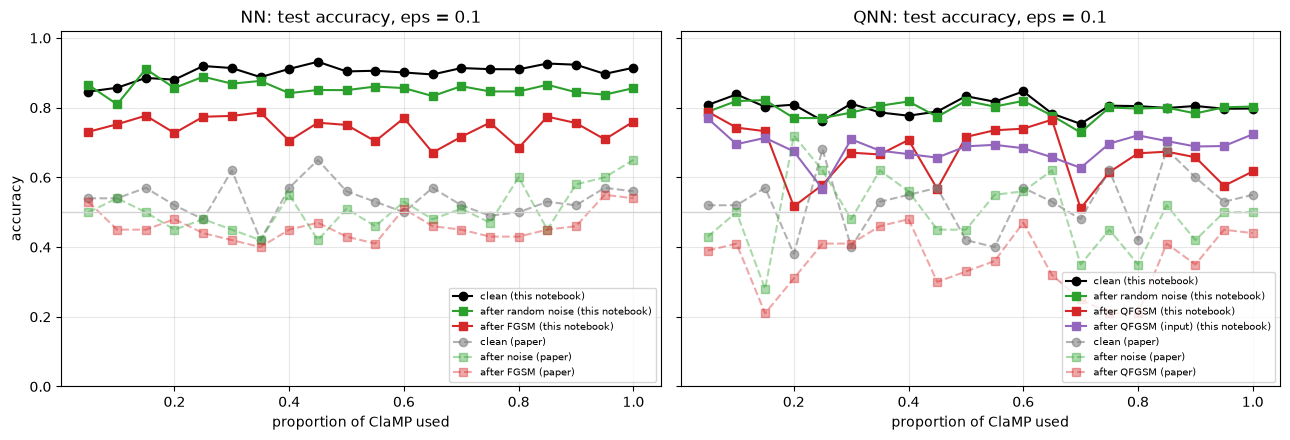

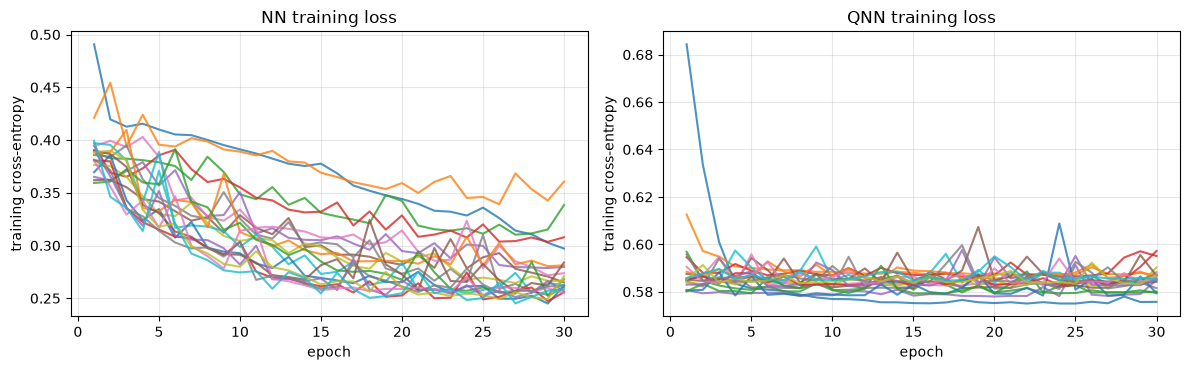

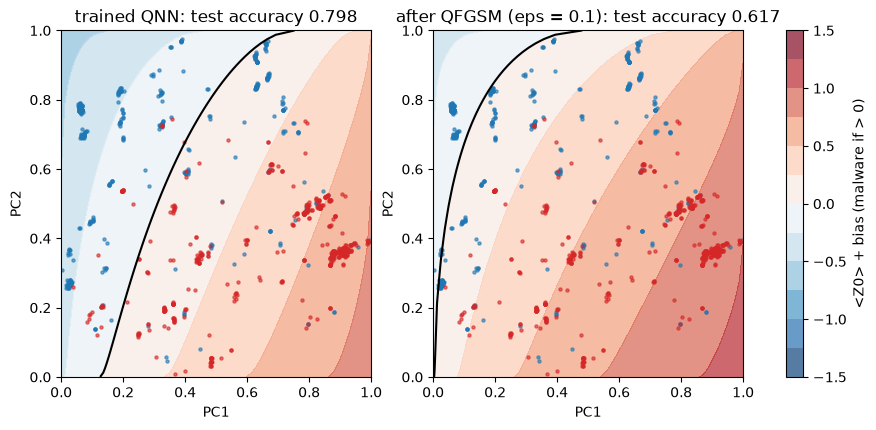

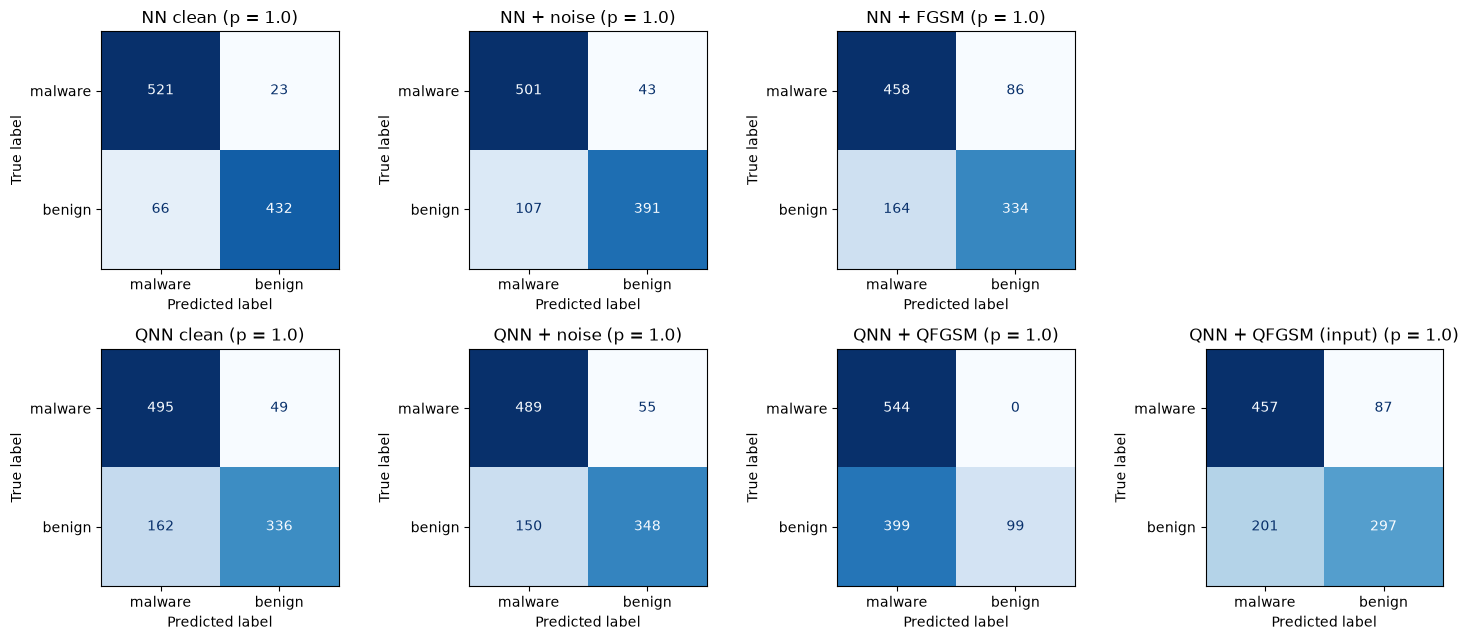

              precision    recall  f1-score   support

 malware (1)      0.753     0.910     0.824       544
  benign (0)      0.873     0.675     0.761       498

    accuracy                          0.798      1042
   macro avg      0.813     0.792     0.793      1042
weighted avg      0.810     0.798     0.794      1042



In [10]:
def paper_style_table(attack_nn, attack_qnn):
    parts = []
    for model, attack in [("NN", attack_nn), ("QNN", attack_qnn)]:
        sub = results[(results.model == model) & (results.attack == attack)]
        tab = sub.pivot(index="proportion", columns="phase", values=["accuracy", "precision", "recall", "f1"])
        tab = tab.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0, sort_remaining=False)[["before", "after"]]
        tab.insert(0, ("", "model"), model)
        parts.append(tab)
    return pd.concat(parts).round(2)

print("This notebook's Table I: random noise, eps =", EPS)
display(paper_style_table("random noise", "random noise"))
print("This notebook's Table II: FGSM on the NN, QFGSM (Algorithm 4, parameter space) on the QNN, eps =", EPS)
display(paper_style_table("FGSM", "QFGSM"))

# ---- accuracy versus proportion, paper's values overlaid ----
PAPER_ACC = {  # accuracy columns of the paper's Table I (noise) and Table II (FGSM/QFGSM), before / after
    "NN before":        [0.54, 0.54, 0.57, 0.52, 0.48, 0.62, 0.42, 0.57, 0.65, 0.56, 0.53, 0.50, 0.57, 0.52, 0.49, 0.50, 0.53, 0.52, 0.57, 0.56],
    "NN noise":         [0.50, 0.54, 0.50, 0.45, 0.48, 0.45, 0.42, 0.55, 0.42, 0.51, 0.46, 0.53, 0.48, 0.51, 0.47, 0.60, 0.45, 0.58, 0.60, 0.65],
    "NN FGSM":          [0.53, 0.45, 0.45, 0.48, 0.44, 0.42, 0.40, 0.45, 0.47, 0.43, 0.41, 0.51, 0.46, 0.45, 0.43, 0.43, 0.45, 0.46, 0.55, 0.54],
    "QNN before":       [0.52, 0.52, 0.57, 0.38, 0.68, 0.40, 0.53, 0.55, 0.57, 0.42, 0.40, 0.57, 0.53, 0.48, 0.62, 0.42, 0.68, 0.60, 0.53, 0.55],
    "QNN noise":        [0.43, 0.50, 0.28, 0.72, 0.62, 0.48, 0.62, 0.56, 0.45, 0.45, 0.55, 0.56, 0.62, 0.35, 0.45, 0.35, 0.52, 0.42, 0.50, 0.50],
    "QNN QFGSM":        [0.39, 0.41, 0.21, 0.31, 0.41, 0.41, 0.46, 0.48, 0.30, 0.33, 0.36, 0.47, 0.32, 0.25, 0.21, 0.21, 0.41, 0.35, 0.45, 0.44]}
PAPER_P = [round(0.05 * k, 2) for k in range(1, 21)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, model, attacks in [(axes[0], "NN", ["random noise", "FGSM"]), (axes[1], "QNN", ["random noise", "QFGSM", "QFGSM (input)"])]:
    before = results[(results.model == model) & (results.attack == attacks[0]) & (results.phase == "before")]
    ax.plot(before.proportion, before.accuracy, "o-", color="black", label="clean (this notebook)")
    for attack, col in zip(attacks, ["tab:green", "tab:red", "tab:purple"]):
        after = results[(results.model == model) & (results.attack == attack) & (results.phase == "after")]
        ax.plot(after.proportion, after.accuracy, "s-", color=col, label=f"after {attack} (this notebook)")
    ax.plot(PAPER_P, PAPER_ACC[f"{model} before"], "o--", color="gray", alpha=0.6, label="clean (paper)")
    ax.plot(PAPER_P, PAPER_ACC[f"{model} noise"], "s--", color="tab:green", alpha=0.4, label="after noise (paper)")
    ax.plot(PAPER_P, PAPER_ACC[f"{model} {'FGSM' if model == 'NN' else 'QFGSM'}"], "s--", color="tab:red", alpha=0.4,
            label=f"after {'FGSM' if model == 'NN' else 'QFGSM'} (paper)")
    ax.axhline(0.5, color="lightgray", lw=1); ax.set_xlabel("proportion of ClaMP used"); ax.set_title(f"{model}: test accuracy, eps = {EPS}")
    ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("accuracy")
plt.tight_layout(); plt.show()

# ---- training loss curves ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, model in zip(axes, ["NN", "QNN"]):
    for p in PROPORTIONS:
        ax.plot(range(1, EPOCHS + 1), losses[p][model], label=f"p = {p:.2f}", alpha=0.8)
    ax.set_xlabel("epoch"); ax.set_ylabel("training cross-entropy"); ax.set_title(f"{model} training loss"); ax.grid(alpha=0.3)
    if len(PROPORTIONS) <= 6: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- QNN decision regions on the PCA plane, before and after QFGSM (largest proportion) ----
p_max = max(PROPORTIONS); s = sections[p_max]; w, b = models[p_max]["qnn"]
w_adv, b_adv = quantum_fgsm(w, b, s["X_train"], s["y_train"], EPS)
g = np.linspace(0, 1, 81); G1, G2 = np.meshgrid(g, g); grid = np.c_[G1.ravel(), G2.ravel()]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (ww, bb), title in [(axes[0], (w, b), "trained QNN"), (axes[1], (w_adv, b_adv), f"after QFGSM (eps = {EPS})")]:
    out = np.asarray(variational_classifier(ww, bb, grid)).reshape(G1.shape)
    cs = ax.contourf(G1, G2, out, levels=np.linspace(-1.5, 1.5, 13), cmap="RdBu_r", alpha=0.7)
    ax.contour(G1, G2, out, levels=[0.0], colors="k")
    for cls, col in [(0, "tab:blue"), (1, "tab:red")]:
        m = s["y_test"] == cls
        ax.scatter(s["X_test"][m, 0], s["X_test"][m, 1], s=5, c=col, alpha=0.6)
    acc = metrics(s["y_test"], qnn_predict(ww, bb, s["X_test"]))["accuracy"]
    ax.set_title(f"{title}: test accuracy {acc:.3f}"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.colorbar(cs, ax=axes, label="<Z0> + bias (malware if > 0)")
plt.show()

# ---- confusion matrices at the largest proportion ----
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, (key, title) in zip(axes.ravel(), [("nn_before", "NN clean"), ("nn_noise", "NN + noise"), ("nn_fgsm", "NN + FGSM"), (None, None),
                                           ("q_before", "QNN clean"), ("q_noise", "QNN + noise"), ("q_qfgsm", "QNN + QFGSM"), ("q_qfgsm_x", "QNN + QFGSM (input)")]):
    if key is None:
        ax.axis("off"); continue
    cm = confusion_matrix(preds["y"], preds[key], labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["malware", "benign"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{title} (p = {p_max})")
plt.tight_layout(); plt.show()
print(classification_report(preds["y"], preds["q_before"], labels=[1, 0], target_names=["malware (1)", "benign (0)"], digits=3))

## 8. How much does $\epsilon$ matter, and how noisy are the numbers?

The paper never states $\epsilon$, although every "after" number depends on it. The sweep below applies all four attacks to
the models trained at the largest proportion for $\epsilon$ from 0 to 0.5. The second cell retrains both models at the largest
proportion with further seeds and reports mean +- standard deviation of the clean and attacked accuracies, which is the
noise band against which the paper's single-run differences should be read.

,NN noise,NN FGSM,QNN noise,QNN QFGSM (parameters),QNN QFGSM (input)
eps,,,,,
0.00,0.915,0.915,0.798,0.798,0.798
0.02,0.907,0.878,0.802,0.795,0.791
0.05,0.893,0.792,0.811,0.807,0.775
0.10,0.857,0.760,0.801,0.617,0.724
0.20,0.785,0.450,0.769,0.522,0.441
0.30,0.733,0.250,0.715,0.522,0.308
0.50,0.661,0.220,0.641,0.522,0.000


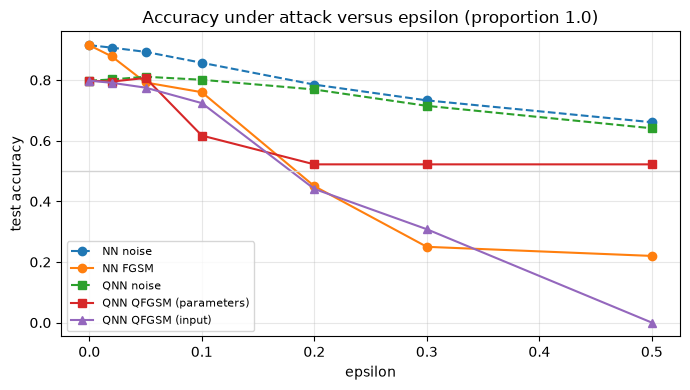

In [11]:
p_max = max(PROPORTIONS); s = sections[p_max]
nn_params = models[p_max]["nn"]; w, b = models[p_max]["qnn"]
Xte, yte, Xtr, ytr = s["X_test"], s["y_test"], s["X_train"], s["y_train"]
sweep = []
for eps in EPS_SWEEP:
    r = np.random.default_rng(SEED + 7)
    w_adv, b_adv = quantum_fgsm(w, b, Xtr, ytr, eps)
    sweep.append({"eps": eps,
                  "NN noise": metrics(yte, nn_predict(nn_params, add_perturbation(Xte, eps, r)))["accuracy"],
                  "NN FGSM": metrics(yte, nn_predict(nn_params, fgsm_nn(nn_params, Xte, yte, eps)))["accuracy"],
                  "QNN noise": metrics(yte, qnn_predict(w, b, add_perturbation(Xte, eps, r)))["accuracy"],
                  "QNN QFGSM (parameters)": metrics(yte, qnn_predict(w_adv, b_adv, Xte))["accuracy"],
                  "QNN QFGSM (input)": metrics(yte, qnn_predict(w, b, qfgsm_input(w, b, Xte, yte, eps)))["accuracy"]})
sweep_df = pd.DataFrame(sweep).set_index("eps").round(3)
display(sweep_df)
fig, ax = plt.subplots(figsize=(7, 4))
for col, style in zip(sweep_df.columns, ["o--", "o-", "s--", "s-", "^-"]):
    ax.plot(sweep_df.index, sweep_df[col], style, label=col)
ax.axhline(0.5, color="lightgray", lw=1); ax.set_xlabel("epsilon"); ax.set_ylabel("test accuracy")
ax.set_title(f"Accuracy under attack versus epsilon (proportion {p_max})"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
rep_rows = []
def eval_all(nn_params, w, b, seed_tag):
    r = np.random.default_rng(seed_tag + 99)
    X_noisy = add_perturbation(Xte, EPS, r)
    w_adv, b_adv = quantum_fgsm(w, b, Xtr, ytr, EPS)
    return {"seed": seed_tag,
            "NN clean": metrics(yte, nn_predict(nn_params, Xte))["accuracy"],
            "NN noise": metrics(yte, nn_predict(nn_params, X_noisy))["accuracy"],
            "NN FGSM": metrics(yte, nn_predict(nn_params, fgsm_nn(nn_params, Xte, yte, EPS)))["accuracy"],
            "QNN clean": metrics(yte, qnn_predict(w, b, Xte))["accuracy"],
            "QNN noise": metrics(yte, qnn_predict(w, b, X_noisy))["accuracy"],
            "QNN QFGSM": metrics(yte, qnn_predict(w_adv, b_adv, Xte))["accuracy"],
            "QNN QFGSM (input)": metrics(yte, qnn_predict(w, b, qfgsm_input(w, b, Xte, yte, EPS)))["accuracy"],
            "QNN F1 clean": metrics(yte, qnn_predict(w, b, Xte))["f1"],
            "QNN F1 QFGSM": metrics(yte, qnn_predict(w_adv, b_adv, Xte))["f1"]}
rep_rows.append(eval_all(nn_params, w, b, SEED))                       # the run of Section 6
t0 = time.perf_counter()
for sd in REPEAT_SEEDS:                                                # same split and inputs, different initialisation / batches
    nn_p, _ = train_nn(Xtr, ytr, sd); ww, bb, _ = train_qnn(Xtr, ytr, sd)
    rep_rows.append(eval_all(nn_p, ww, bb, sd))
print(f"repeats took {(time.perf_counter() - t0) / 60:.1f} min")
rep_df = pd.DataFrame(rep_rows).set_index("seed")
display(rep_df.round(3))
rep_summary = rep_df.agg(["mean", "std"]).T.round(3)
print(f"mean +- std over {len(rep_df)} seeds at proportion {p_max}:")
display(rep_summary)

repeats took 3.9 min


,NN clean,NN noise,NN FGSM,QNN clean,QNN noise,QNN QFGSM,QNN QFGSM (input),QNN F1 clean,QNN F1 QFGSM
seed,,,,,,,,,
42,0.915,0.871,0.760,0.798,0.814,0.617,0.724,0.824,0.732
43,0.911,0.858,0.764,0.836,0.816,0.645,0.718,0.852,0.746
44,0.916,0.863,0.800,0.787,0.739,0.522,0.528,0.830,0.686


mean +- std over 3 seeds at proportion 1.0:


,mean,std
NN clean,0.914,0.003
NN noise,0.864,0.007
NN FGSM,0.775,0.022
QNN clean,0.807,0.026
QNN noise,0.790,0.044
QNN QFGSM,0.595,0.064
QNN QFGSM (input),0.656,0.111
QNN F1 clean,0.836,0.015
QNN F1 QFGSM,0.721,0.031


## 9. Paper versus this notebook

Each row of the first table is one accuracy or F1 value from the paper's Tables I and II for a proportion that this run
covers. The verdict is **reproduced** when our value lies within 0.02 of the paper's (the brief's tolerance: 2 accuracy
points / 0.02 F1), **exceeded** when it is more than 0.02 above, **not reached** when more than 0.02 below. Because the paper's
models hover around chance (0.4-0.6) while the same data and pipeline give 0.8-0.95 here, almost every "before" row is
*exceeded*; what can be compared meaningfully are the paper's qualitative claims, which the second table checks.

In [13]:
PAPER_TABLE_I = '''
NN  0.05 0.54 1.00 0.54 0.70 | 0.50 0.62 0.45 0.62
NN  0.10 0.54 1.00 0.54 0.70 | 0.54 1.00 0.54 0.70
NN  0.15 0.57 0.94 0.57 0.67 | 0.50 0.50 1.00 0.67
NN  0.20 0.52 0.81 0.53 0.60 | 0.45 0.00 0.00 0.00
NN  0.25 0.48 0.92 0.47 0.56 | 0.48 1.00 0.16 0.28
NN  0.30 0.62 1.00 0.62 0.77 | 0.45 0.41 1.00 0.58
NN  0.35 0.42 0.71 0.42 0.52 | 0.42 0.46 0.80 0.58
NN  0.40 0.57 0.98 0.57 0.71 | 0.55 0.00 0.00 0.00
NN  0.45 0.65 0.87 0.65 0.71 | 0.42 0.42 1.00 0.60
NN  0.50 0.56 1.00 0.48 0.65 | 0.51 1.00 0.51 0.68
NN  0.55 0.53 1.00 0.53 0.70 | 0.46 1.00 0.46 0.63
NN  0.60 0.50 1.00 0.50 0.66 | 0.53 1.00 0.53 0.69
NN  0.65 0.57 1.00 0.57 0.72 | 0.48 1.00 0.48 0.65
NN  0.70 0.52 1.00 0.52 0.68 | 0.51 1.00 0.51 0.68
NN  0.75 0.49 1.00 0.49 0.66 | 0.47 1.00 0.47 0.64
NN  0.80 0.50 1.00 0.50 0.67 | 0.60 1.00 0.60 0.75
NN  0.85 0.53 1.00 0.53 0.69 | 0.45 1.00 0.45 0.62
NN  0.90 0.52 1.00 0.52 0.69 | 0.58 1.00 0.58 0.74
NN  0.95 0.57 0.55 0.55 0.55 | 0.60 0.62 0.62 0.62
NN  1.00 0.56 0.55 0.55 0.55 | 0.65 0.64 0.66 0.64
QNN 0.05 0.52 0.84 0.52 0.64 | 0.43 0.53 0.24 0.33
QNN 0.10 0.52 0.98 0.53 0.66 | 0.50 0.50 1.00 0.67
QNN 0.15 0.57 0.92 0.57 0.65 | 0.28 0.17 0.04 0.06
QNN 0.20 0.38 0.53 0.38 0.43 | 0.72 0.71 0.87 0.78
QNN 0.25 0.68 0.87 0.68 0.70 | 0.62 0.66 0.84 0.74
QNN 0.30 0.40 0.92 0.40 0.56 | 0.48 0.47 0.89 0.62
QNN 0.35 0.53 0.76 0.53 0.62 | 0.62 0.61 0.96 0.75
QNN 0.40 0.55 0.57 0.68 0.62 | 0.56 0.56 0.59 0.56
QNN 0.45 0.57 0.87 0.57 0.66 | 0.45 0.47 0.90 0.62
QNN 0.50 0.42 0.51 0.42 0.45 | 0.45 0.47 0.85 0.61
QNN 0.55 0.40 0.62 0.40 0.49 | 0.55 1.00 0.25 0.40
QNN 0.60 0.57 0.87 0.57 0.66 | 0.56 0.00 0.00 0.00
QNN 0.65 0.53 0.81 0.53 0.64 | 0.62 0.62 1.00 0.77
QNN 0.70 0.48 0.79 0.47 0.51 | 0.35 0.38 0.82 0.52
QNN 0.75 0.62 0.82 0.62 0.66 | 0.45 0.00 0.00 0.00
QNN 0.80 0.42 0.79 0.42 0.55 | 0.35 0.46 0.54 0.50
QNN 0.85 0.68 0.89 0.68 0.71 | 0.52 0.53 1.00 0.69
QNN 0.90 0.60 0.79 0.60 0.65 | 0.42 0.45 0.89 0.60
QNN 0.95 0.53 0.52 0.54 0.52 | 0.50 0.53 0.54 0.53
QNN 1.00 0.55 0.53 0.54 0.53 | 0.50 0.52 0.52 0.52
'''
PAPER_TABLE_II = '''
NN  0.05 0.54 1.00 0.54 0.70 | 0.53 1.00 0.53 0.70
NN  0.10 0.54 1.00 0.54 0.70 | 0.45 0.65 0.51 0.60
NN  0.15 0.57 0.94 0.57 0.67 | 0.45 0.45 0.55 0.50
NN  0.20 0.52 0.81 0.53 0.60 | 0.48 0.50 0.52 0.54
NN  0.25 0.48 0.92 0.47 0.56 | 0.44 0.53 0.55 0.52
NN  0.30 0.62 1.00 0.62 0.77 | 0.42 0.42 0.42 0.53
NN  0.35 0.42 0.71 0.42 0.52 | 0.40 0.41 0.41 0.50
NN  0.40 0.57 0.98 0.57 0.71 | 0.45 0.45 0.45 0.45
NN  0.45 0.65 0.87 0.65 0.71 | 0.47 0.45 0.43 0.46
NN  0.50 0.56 1.00 0.48 0.65 | 0.43 0.43 0.44 0.45
NN  0.55 0.53 1.00 0.53 0.70 | 0.41 0.47 0.46 0.48
NN  0.60 0.50 1.00 0.50 0.66 | 0.51 0.55 0.55 0.55
NN  0.65 0.57 1.00 0.57 0.72 | 0.46 0.46 0.48 0.49
NN  0.70 0.52 1.00 0.52 0.68 | 0.45 0.45 0.45 0.55
NN  0.75 0.49 1.00 0.49 0.66 | 0.43 0.44 0.41 0.42
NN  0.80 0.50 1.00 0.50 0.67 | 0.43 0.45 0.45 0.45
NN  0.85 0.53 1.00 0.53 0.69 | 0.45 0.56 0.54 0.55
NN  0.90 0.52 1.00 0.52 0.69 | 0.46 0.55 0.56 0.58
NN  0.95 0.57 0.55 0.55 0.55 | 0.55 0.58 0.58 0.58
NN  1.00 0.56 0.55 0.55 0.55 | 0.54 0.55 0.55 0.55
QNN 0.05 0.52 0.84 0.52 0.64 | 0.39 0.42 0.25 0.30
QNN 0.10 0.52 0.98 0.53 0.66 | 0.41 0.42 0.42 0.42
QNN 0.15 0.57 0.92 0.57 0.65 | 0.21 0.00 0.00 0.00
QNN 0.20 0.38 0.53 0.38 0.43 | 0.31 0.45 0.45 0.45
QNN 0.25 0.68 0.87 0.68 0.70 | 0.41 0.39 0.46 0.44
QNN 0.30 0.40 0.92 0.40 0.56 | 0.41 0.43 0.37 0.41
QNN 0.35 0.53 0.76 0.53 0.62 | 0.46 0.37 0.35 0.38
QNN 0.40 0.55 0.57 0.68 0.71 | 0.48 0.55 0.56 0.55
QNN 0.45 0.57 0.87 0.57 0.66 | 0.30 0.34 0.37 0.36
QNN 0.50 0.42 0.51 0.42 0.45 | 0.33 0.36 0.39 0.40
QNN 0.55 0.40 0.62 0.40 0.49 | 0.36 0.35 0.37 0.40
QNN 0.60 0.57 0.87 0.57 0.51 | 0.47 0.45 0.43 0.41
QNN 0.65 0.53 0.81 0.53 0.64 | 0.32 0.38 0.27 0.31
QNN 0.70 0.48 0.79 0.47 0.51 | 0.25 0.27 0.32 0.32
QNN 0.75 0.62 0.82 0.62 0.66 | 0.21 0.20 0.20 0.20
QNN 0.80 0.42 0.79 0.42 0.55 | 0.21 0.23 0.22 0.20
QNN 0.85 0.68 0.89 0.68 0.71 | 0.41 0.43 0.44 0.42
QNN 0.90 0.60 0.79 0.60 0.65 | 0.35 0.36 0.36 0.37
QNN 0.95 0.53 0.52 0.54 0.52 | 0.45 0.48 0.48 0.48
QNN 1.00 0.55 0.53 0.54 0.53 | 0.44 0.45 0.45 0.45
'''
def parse_paper(txt, table):
    out = []
    for line in txt.strip().splitlines():
        model, p, *vals = line.replace("|", " ").split()
        v = list(map(float, vals))
        attack = "random noise" if table == "I" else ("FGSM" if model == "NN" else "QFGSM")
        for phase, k in [("before", 0), ("after", 4)]:
            out.append(dict(table=table, model=model, attack=attack, proportion=float(p), phase=phase,
                            accuracy=v[k], precision=v[k + 1], recall=v[k + 2], f1=v[k + 3]))
    return out
paper = pd.DataFrame(parse_paper(PAPER_TABLE_I, "I") + parse_paper(PAPER_TABLE_II, "II"))
# typos in the printed tables: "0. 28", "0. 21" and "35" were read as 0.28, 0.21 and 0.35

TOL = 0.02
def verdict(paper_v, ours):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "not run here"
    if abs(ours - paper_v) <= TOL:
        return "reproduced"
    return "exceeded (+%.2f)" % (ours - paper_v) if ours > paper_v else "not reached (%.2f)" % (ours - paper_v)

ours = results[results.attack.isin(["random noise", "FGSM", "QFGSM"])].copy()
merged = paper.merge(ours, on=["model", "attack", "proportion", "phase"], how="left", suffixes=("_paper", "_nb"))
comp_rows = []
for _, r in merged.iterrows():
    for metric in ["accuracy", "f1"]:
        comp_rows.append(dict(table=r["table"], model=r["model"], attack=r["attack"], proportion=r["proportion"], phase=r["phase"],
                              metric=metric, paper=r[f"{metric}_paper"], notebook=None if pd.isna(r[f"{metric}_nb"]) else round(r[f"{metric}_nb"], 3),
                              verdict=verdict(r[f"{metric}_paper"], None if pd.isna(r[f"{metric}_nb"]) else float(r[f"{metric}_nb"]))))
comparison = pd.DataFrame(comp_rows)
print("Per-number comparison (accuracy and F1 of the paper's Tables I and II, proportions run here):")
with pd.option_context("display.max_rows", 400):
    display(comparison[comparison.notebook.notna()])
print("\nverdict counts:"); print(comparison[comparison.notebook.notna()].verdict.str.split(" ").str[0].value_counts().to_string())

# ---- the paper's qualitative claims ----
def acc(model, attack, phase):
    return results[(results.model == model) & (results.attack == attack) & (results.phase == phase)].set_index("proportion").accuracy
drop_q_qfgsm = (acc("QNN", "QFGSM", "before") - acc("QNN", "QFGSM", "after")).mean()
drop_q_noise = (acc("QNN", "random noise", "before") - acc("QNN", "random noise", "after")).mean()
drop_nn_fgsm = (acc("NN", "FGSM", "before") - acc("NN", "FGSM", "after")).mean()
drop_nn_noise = (acc("NN", "random noise", "before") - acc("NN", "random noise", "after")).mean()
claims = [
    ("QNN is more vulnerable to QFGSM than to random noise (abstract)",
     "mean accuracy drop QFGSM > noise", f"QFGSM drop {drop_q_qfgsm:.3f} vs noise drop {drop_q_noise:.3f}",
     "reproduced" if drop_q_qfgsm > drop_q_noise + TOL else "not reproduced"),
    ("QFGSM damages the QNN more than FGSM damages the NN (Section IV)",
     "paper: QNN min 0.21 vs NN min 0.40", f"mean drops: QNN/QFGSM {drop_q_qfgsm:.3f} vs NN/FGSM {drop_nn_fgsm:.3f}; minima "
     f"{acc('QNN', 'QFGSM', 'after').min():.2f} vs {acc('NN', 'FGSM', 'after').min():.2f}",
     "reproduced" if drop_q_qfgsm > drop_nn_fgsm + TOL else "not reproduced (the NN loses at least as much under input-space FGSM)"),
    ("Random noise sometimes leaves accuracy unchanged or higher (Section IV)",
     "any proportion with after >= before", f"{int(((acc('NN', 'random noise', 'after') >= acc('NN', 'random noise', 'before')) | (acc('QNN', 'random noise', 'after') >= acc('QNN', 'random noise', 'before'))).sum())} of {len(PROPORTIONS)} proportions",
     "reproduced" if (((acc('NN', 'random noise', 'after') >= acc('NN', 'random noise', 'before')) | (acc('QNN', 'random noise', 'after') >= acc('QNN', 'random noise', 'before'))).any()) else "not reproduced"),
    ("Highest clean accuracy: NN 0.62, QNN 0.68 (Section IV)", "max over proportions",
     f"NN {acc('NN', 'FGSM', 'before').max():.2f}, QNN {acc('QNN', 'QFGSM', 'before').max():.2f}",
     f"NN {verdict(0.62, float(acc('NN', 'FGSM', 'before').max()))}; QNN {verdict(0.68, float(acc('QNN', 'QFGSM', 'before').max()))}"),
    ("Lowest post-attack accuracy: NN/FGSM 0.40, QNN/QFGSM 0.21 (Section IV)", "min over proportions",
     f"NN {acc('NN', 'FGSM', 'after').min():.2f}, QNN {acc('QNN', 'QFGSM', 'after').min():.2f}",
     f"NN {verdict(0.40, float(acc('NN', 'FGSM', 'after').min()))}; QNN {verdict(0.21, float(acc('QNN', 'QFGSM', 'after').min()))}"),
    ("NN and QNN performance before attack is 'relatively strong' (0.4-0.68)", "clean accuracy at the largest proportion",
     f"NN {acc('NN', 'FGSM', 'before')[max(PROPORTIONS)]:.2f}, QNN {acc('QNN', 'QFGSM', 'before')[max(PROPORTIONS)]:.2f}; "
     f"RF / SVC on the same inputs {baseline_df[(baseline_df.proportion == max(PROPORTIONS)) & (baseline_df.inputs == '2 PCA components')].acc_clean.max():.2f}",
     "exceeded: the paper's models are at chance level on a dataset that is easy on these inputs"),
    ("ROC curves (Section IV)", "not printed in the paper", "not computed", "cannot be checked"),
]
claims_df = pd.DataFrame(claims, columns=["claim", "how checked", "this notebook", "verdict"])
with pd.option_context("display.max_colwidth", 120):
    display(claims_df)

Per-number comparison (accuracy and F1 of the paper's Tables I and II, proportions run here):


,table,model,attack,proportion,phase,metric,paper,notebook,verdict
0,I,NN,random noise,0.05,before,accuracy,0.54,0.846,exceeded (+0.31)
1,I,NN,random noise,0.05,before,f1,0.70,0.846,exceeded (+0.15)
2,I,NN,random noise,0.05,after,accuracy,0.50,0.865,exceeded (+0.37)
3,I,NN,random noise,0.05,after,f1,0.62,0.868,exceeded (+0.25)
4,I,NN,random noise,0.10,before,accuracy,0.54,0.857,exceeded (+0.32)
5,I,NN,random noise,0.10,before,f1,0.70,0.851,exceeded (+0.15)
6,I,NN,random noise,0.10,after,accuracy,0.54,0.810,exceeded (+0.27)
7,I,NN,random noise,0.10,after,f1,0.70,0.792,exceeded (+0.09)
8,I,NN,random noise,0.15,before,accuracy,0.57,0.885,exceeded (+0.32)
9,I,NN,random noise,0.15,before,f1,0.67,0.894,exceeded (+0.22)



verdict counts:
verdict
exceeded      315
not             4
reproduced      1


,claim,how checked,this notebook,verdict
0,QNN is more vulnerable to QFGSM than to random noise (abstract),mean accuracy drop QFGSM > noise,QFGSM drop 0.139 vs noise drop 0.007,reproduced
1,QFGSM damages the QNN more than FGSM damages the NN (Section IV),paper: QNN min 0.21 vs NN min 0.40,mean drops: QNN/QFGSM 0.139 vs NN/FGSM 0.160; minima 0.51 vs 0.67,not reproduced (the NN loses at least as much under input-space FGSM)
2,Random noise sometimes leaves accuracy unchanged or higher (Section IV),any proportion with after >= before,8 of 20 proportions,reproduced
3,"Highest clean accuracy: NN 0.62, QNN 0.68 (Section IV)",max over proportions,"NN 0.93, QNN 0.85",NN exceeded (+0.31); QNN exceeded (+0.17)
4,"Lowest post-attack accuracy: NN/FGSM 0.40, QNN/QFGSM 0.21 (Section IV)",min over proportions,"NN 0.67, QNN 0.51",NN exceeded (+0.27); QNN exceeded (+0.30)
5,NN and QNN performance before attack is 'relatively strong' (0.4-0.68),clean accuracy at the largest proportion,"NN 0.91, QNN 0.80; RF / SVC on the same inputs 0.96",exceeded: the paper's models are at chance level on a dataset that is easy on these inputs
6,ROC curves (Section IV),not printed in the paper,not computed,cannot be checked


## Reading the paper critically

**The paper's models never learn the task.** Every "before" accuracy in Tables I and II lies between 0.38 and 0.68, and the
NN rows show precision 1.00 with recall equal to the accuracy (0.54 / 0.54 / 0.70), which is the signature of a classifier
that predicts one class for every row (with the labels or the averaging swapped). On the same public file, the same 2-component
PCA and the same circuit, this notebook's QNN reaches 0.8-0.9 accuracy and a random forest on the same two numbers about
0.95, in seconds. A model at chance level cannot tell us much about adversarial vulnerability: when the clean accuracy is
0.5, an "attack" that moves it to 0.4 or 0.6 is within the noise of a 50-row test set (at proportion 0.05 the test split has
about 50 rows, so one standard error of the accuracy is about 0.07).

**"Quantum FGSM" is not an adversarial-example attack.** FGSM perturbs the *input* so that a fixed model misclassifies it. The
paper's Algorithm 4 perturbs the *trained weights and bias* of the circuit by $\epsilon\,\mathrm{sign}(\nabla \mathcal{L})$, i.e. it
undoes one signed gradient step of training. That is a model-corruption (or fault-injection) attack, and it is not
quantum-specific: the identical rule applied to any classical model's parameters would also degrade it (exercise 2). The
comparison "QNN under QFGSM versus NN under FGSM" therefore compares two different threat models. Sections 6 and 8 show the
fair comparison: the input-space FGSM applied to the QNN through its encoding (our addition) degrades it at least as much as
it degrades the NN at the same $\epsilon$, while the effect of the parameter-space rule is entirely a function of $\epsilon$:
at 0.1 rad it costs the QNN between 2 and 30 accuracy points depending on the proportion and the seed (mean about 0.14),
at 0.2 rad the 12-parameter circuit collapses to predicting a single class (accuracy = the majority share), because every
weight is an angle of order one and a signed step of 0.2 on all twelve at once is not a "small perturbation".

**$\epsilon$, epochs, layers, learning rate, split and NN architecture are not reported.** The size of every "after" number is a
direct function of $\epsilon$ (the sweep in Section 8 goes from no effect to chance level within 0.0-0.3), yet the paper gives
no value. Nothing in the paper says which rows formed the 20 proportions, how the test set was chosen, or whether the "after"
metrics were computed on perturbed training data (as the text of Algorithm 3 says, "we add random perturbations to the training
dataset") or on perturbed test data. Our verdicts are therefore about the direction and size of the effects, not their third
decimal.

**Inconsistencies in the printed tables.** The "before" columns of Tables I and II should be identical (same models, attack
not yet applied); they differ for the QNN at proportions 0.40 (F1 0.62 vs 0.71) and 0.60 (F1 0.66 vs 0.51). The text says
the QNN "improved slightly from 0.50 to 0.52" under noise at proportion 0.15, but Table I prints 0.57 -> 0.28 there. The
dataset is called "5,184 samples" in Section III.A and "5,210 rows" in III.B (the public file is named `-5184` and has 5,210
rows). Several cells are typographically broken ("0. 28", "35"). Precision 0.00 with accuracy 0.45 (NN, noise, 0.20) means the
attacked model predicted *benign* for everything, which is consistent with a model that was barely trained.

**What does hold up.** The qualitative statements are easy to confirm with properly trained models: random Gaussian noise of
the same magnitude hurts far less than a gradient-sign attack, the parameter-space QFGSM of Algorithm 4 does cut the QNN's
accuracy sharply for $\epsilon \gtrsim 0.1$, and the shallow 2-qubit circuit is a reasonable classifier of ClaMP's first two
principal components. What the paper does not show is any *quantum-specific* vulnerability, because its quantum attack is
not quantum-specific and its classical baseline is a different attack on a different model.

## Exercises

1. **Noise band.** Set `REPEAT_SEEDS = [43, 44, 45, 46]` and rerun Section 8. Are the paper's between-proportion differences
   (e.g. QNN 0.68 at 0.25 versus 0.38 at 0.20) larger than the standard deviation you obtain at a single proportion?
2. **A fair comparison.** Apply Algorithm 4 to the classical NN (perturb `W1, b1, W2, b2` by $\epsilon\,\mathrm{sign}(\nabla)$)
   and compare its accuracy drop with the QNN's under the same rule. Is the QNN really "more vulnerable", or is the
   parameter-space rule simply stronger than the input-space one at this $\epsilon$?
3. **Epsilon in the right units.** The QNN weights are angles. Re-express the QFGSM step as a fraction of each weight's
   magnitude (relative $\epsilon$) and redo the sweep of Section 8. At what relative step does the model fall to chance?
4. **Encoding matters.** Replace the paper's $\arccos\sqrt{x}$ encoding by a plain $\pi x$ rotation and by Qiskit-style
   $x \in [0, \pi]$ scaling, keeping everything else fixed. Which encoding gives the best clean accuracy, and which is most
   robust to input-space FGSM at $\epsilon = 0.1$?
5. **More qubits.** Set `N_QUBITS = 4` (PCA to four components) and `N_LAYERS = 3`. Does the clean accuracy approach the
   random forest on the same inputs, and does the parameter-space QFGSM become more or less damaging as the parameter count
   grows?